# Forecasting pemakaian bahan dan saran stok: Banyu Bening

Notebook ini bisa dijalankan dari atas ke bawah di Google Colab (Runtime > Run all). Isinya: persiapan data, fitur, pembandingan model machine learning, evaluasi, forecast 7 hari, dan saran stok.

**Masalah.** Stok bahan sering berlebih (waste, terutama protein dan sayur berumur simpan 2 sampai 5 hari) atau kurang. Tujuannya meramal pemakaian tiap bahan untuk 7 hari ke depan, lalu menurunkannya menjadi saran pembelian.

**Data.** `Dataset_Dummy_Banyu_Bening (1).xlsx`: **seluruhnya sintetis** (seed 20261112), hanya katalog menu yang berasal dari restobanyubening.com. Periode 2026-05-01 sampai 2026-10-31.

**Protokol.** Hanya pembagian waktu (tanpa pengacakan). Dua lipatan bersarang: lipatan A (tuning Agustus, uji September) dan lipatan B (tuning September, uji Oktober).

**Peringatan.** Karena data sintetis, urutan model di sini tidak membuktikan performa di data nyata.

## 1. Persiapan

In [1]:
import sys, subprocess, importlib


def _ensure(pkg, mod=None):
    try:
        importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])


for pkg, mod in [('scikit-learn', 'sklearn'), ('lightgbm', None), ('xgboost', None),
                 ('catboost', None), ('openpyxl', None), ('joblib', None)]:
    _ensure(pkg, mod)

import json, time, warnings
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

SEED = 42
# True = grid tuning lebih kecil (uji cepat). False = grid penuh seperti di laporan.
QUICK_MODE = False
OUT = Path('hasil_forecasting')
OUT.mkdir(exist_ok=True)
print('siap')

siap


## 2. Memuat data

Letakkan file dataset di folder kerja Colab (panel Files di kiri), atau jalankan sel ini dan unggah file saat diminta. File juga dicari di Google Drive (`/content/drive/MyDrive/`).

In [2]:
CANDIDATES = [
    'dataset_banyu_bening.xlsx',
    'Dataset_Dummy_Banyu_Bening (1).xlsx',
    'Dataset_Dummy_Banyu_Bening.xlsx',
    '/content/drive/MyDrive/dataset_banyu_bening.xlsx',
    '/content/drive/MyDrive/Dataset_Dummy_Banyu_Bening (1).xlsx',
    '/data/raw/dataset_banyu_bening.xlsx',
]
path = next((Path(p) for p in CANDIDATES if Path(p).exists()), None)
if path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        path = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError('Dataset tidak ditemukan. Letakkan file .xlsx di folder kerja.')
print('Memakai file:', path)

sheets = pd.read_excel(path, sheet_name=['orders', 'order_items', 'recipes', 'ingredients'])
for name, frame in sheets.items():
    print(f'{name:12s} {frame.shape}')

Saving dataset_banyu_bening.xlsx to dataset_banyu_bening.xlsx
Memakai file: dataset_banyu_bening.xlsx
orders       (2285, 16)
order_items  (5000, 11)
recipes      (1481, 7)
ingredients  (106, 11)


## 3. Validasi data dan pemakaian bahan harian

Pemakaian bahan = `quantity` (order_items) x `qty_per_portion` (recipes), dijumlahkan per bahan per hari. Hanya order dengan `payment_status = paid` yang dipakai (aturan sheet Panduan).

In [3]:
orders = sheets['orders'].copy()
items = sheets['order_items']
recipes = sheets['recipes']
ingredients = sheets['ingredients']
merged = recipes.merge(ingredients[['ingredient_id', 'base_unit']], on='ingredient_id')

quality = {
    'order_total': len(orders),
    'order_paid': int((orders.payment_status == 'paid').sum()),
    'order_dibuang_bukan_paid': int((orders.payment_status != 'paid').sum()),
    'ordered_at_kosong': int(orders.ordered_at.isna().sum()),
    'item_tanpa_order': int((~items.order_id.isin(orders.order_id)).sum()),
    'item_menu_tanpa_resep': int((~items.menu_id.isin(recipes.menu_id)).sum()),
    'satuan_resep_beda': int((merged.unit != merged.base_unit).sum()),
}
print(json.dumps(quality, indent=2))
assert quality['ordered_at_kosong'] == 0, 'ordered_at harus terisi'


def daily_usage(sheets):
    orders = sheets['orders'].copy()
    orders['ordered_at'] = pd.to_datetime(orders['ordered_at'])
    paid = orders.loc[orders.payment_status == 'paid', ['order_id', 'ordered_at']]
    paid['date'] = paid.ordered_at.dt.normalize()
    lines = sheets['order_items'].merge(paid[['order_id', 'date']], on='order_id')
    usage = lines.merge(sheets['recipes'], on='menu_id')
    usage['use'] = usage['quantity'] * usage['qty_per_portion']
    matrix = usage.groupby(['ingredient_id', 'date'])['use'].sum().unstack(fill_value=0.0)
    days = pd.date_range(paid.date.min(), paid.date.max(), freq='D')
    return matrix.reindex(columns=days, fill_value=0.0).reindex(
        sheets['ingredients']['ingredient_id'], fill_value=0.0)


matrix = daily_usage(sheets)
print('Matriks pemakaian:', matrix.shape[0], 'bahan x', matrix.shape[1], 'hari',
      '|', matrix.columns.min().date(), 'sampai', matrix.columns.max().date())

{
  "order_total": 2285,
  "order_paid": 2017,
  "order_dibuang_bukan_paid": 268,
  "ordered_at_kosong": 0,
  "item_tanpa_order": 0,
  "item_menu_tanpa_resep": 0,
  "satuan_resep_beda": 0
}
Matriks pemakaian: 106 bahan x 184 hari | 2026-05-01 sampai 2026-10-31


## 4. Eksplorasi singkat

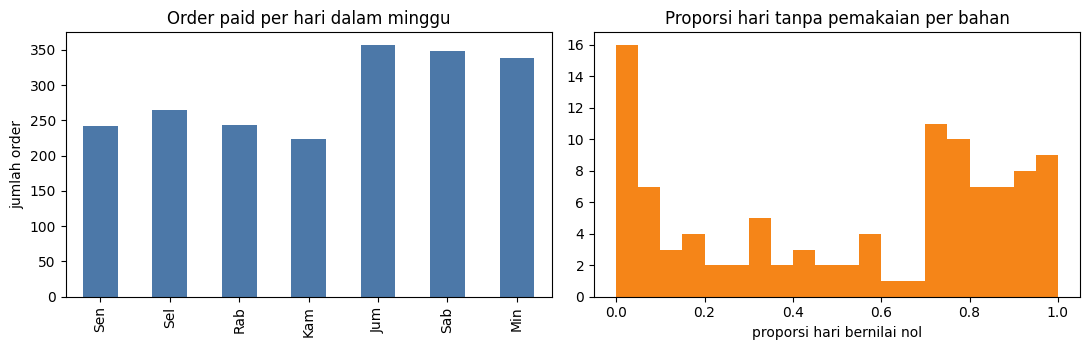

Order paid per hari: rata-rata 11.0
Jumlah bahan dengan >50% hari nol: 60 dari 106


In [4]:
paid = orders[orders.payment_status == 'paid'].copy()
paid['ordered_at'] = pd.to_datetime(paid['ordered_at'])
by_dow = paid.groupby(paid.ordered_at.dt.dayofweek).size()
by_dow.index = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
zero_share = (matrix == 0).mean(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
by_dow.plot.bar(ax=ax[0], color='#4C78A8')
ax[0].set_title('Order paid per hari dalam minggu')
ax[0].set_ylabel('jumlah order')
ax[1].hist(zero_share, bins=20, color='#F58518')
ax[1].set_title('Proporsi hari tanpa pemakaian per bahan')
ax[1].set_xlabel('proporsi hari bernilai nol')
plt.tight_layout()
plt.show()

print('Order paid per hari: rata-rata', round(len(paid) / matrix.shape[1], 1))
print('Jumlah bahan dengan >50% hari nol:', int((zero_share > 0.5).sum()), 'dari', len(zero_share))

## 5. Fitur

Horizon 7 hari tanpa forecast rekursif: setiap fitur riwayat hanya memakai data yang berumur minimal 7 hari terhadap hari target. Satu model dapat meramal hari mana pun dalam 7 hari ke depan dari titik asal yang sama, tanpa kebocoran data.

Target dan fitur riwayat dibagi **skala bahan** (rata-rata pemakaian di periode latih) supaya satu model global tidak didominasi bahan bervolume besar. Skala dan kelompok bahan dihitung hanya dari periode latih tiap lipatan.

Kelompok bahan (dari proporsi hari nol di periode latih): `rutin` (<=40%), `jarang` (40 sampai 90%), `sangat_jarang` (>90%), `tanpa_riwayat` (tidak pernah terpakai; dikeluarkan dari model).

In [5]:
LAGS = (7, 14, 21, 28)
GROUPS = ['rutin', 'jarang', 'sangat_jarang']
V2_EXTRA = ['exp_mean', 'dow_factor', 'g_lag_7', 'g_roll_28', 'pooled_dow', 'roll28_dow']


def ingredient_groups(matrix, train_end):
    train = matrix.loc[:, :train_end]
    zero_share = (train == 0).mean(axis=1)
    scale = train.mean(axis=1)
    group = pd.cut(zero_share, bins=[-0.01, 0.4, 0.9, 0.9999, 1.0],
                   labels=['rutin', 'jarang', 'sangat_jarang', 'tanpa_riwayat'])
    return pd.DataFrame({'zero_share': zero_share, 'scale': scale, 'group': group.astype(str)})


def global_demand_features(matrix, info, keep):
    # Sinyal permintaan total semua bahan (ternormalisasi), hanya dari data berumur >= 7 hari.
    total = matrix.loc[keep].div(info.loc[keep, 'scale'], axis=0).sum(axis=0)
    dow = pd.Series(total.index.dayofweek, index=total.index)
    same_dow = total.groupby(dow).transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
    overall = total.shift(7).expanding(min_periods=7).mean()
    return pd.DataFrame({
        'dow_factor': same_dow / overall,
        'g_lag_7': total.shift(7) / overall,
        'g_roll_28': total.shift(7).rolling(28).mean() / overall,
    })


def build_panel(matrix, ingredients, info):
    keep = info.index[(info.group != 'tanpa_riwayat') & (info.scale > 0)]
    static = ingredients.set_index('ingredient_id')
    market = global_demand_features(matrix, info, keep)
    frames = []
    for ing in keep:
        y = matrix.loc[ing]
        scale = info.loc[ing, 'scale']
        frame = pd.DataFrame({'y_raw': y.values}, index=y.index)
        for lag in LAGS:
            frame[f'lag_{lag}'] = y.shift(lag).values / scale
        frame['roll_mean_7'] = y.shift(7).rolling(7).mean().values / scale
        frame['roll_mean_14'] = y.shift(7).rolling(14).mean().values / scale
        frame['roll_mean_28'] = y.shift(7).rolling(28).mean().values / scale
        frame['roll_nz_28'] = (y.shift(7) > 0).rolling(28).mean().values
        frame['exp_mean'] = y.shift(7).expanding(min_periods=7).mean().values / scale
        frame['ingredient_id'] = ing
        frame['scale'] = scale
        frame['group'] = info.loc[ing, 'group']
        frame['category'] = static.loc[ing, 'ingredient_category']
        frame['unit'] = static.loc[ing, 'base_unit']
        frame['shelf_life_days'] = static.loc[ing, 'shelf_life_days']
        frames.append(frame)
    panel = pd.concat(frames).rename_axis('date').reset_index()
    panel = panel.merge(market, left_on='date', right_index=True, how='left')
    panel['y'] = panel['y_raw'] / panel['scale']
    panel['dow'] = panel['date'].dt.dayofweek
    panel['is_fri_sun'] = panel['dow'].isin([4, 5, 6]).astype(int)
    panel['day_of_month'] = panel['date'].dt.day
    panel['is_month_end'] = (panel['day_of_month'] >= 25).astype(int)
    panel['log_scale'] = np.log1p(panel['scale'])
    panel['log_shelf_life'] = np.log1p(panel['shelf_life_days'])
    # Baseline: bukan model terlatih (dinormalisasi skala bahan).
    panel['seasonal_naive'] = panel['lag_7']
    panel['dow_mean_4w'] = panel[[f'lag_{lag}' for lag in LAGS]].mean(axis=1)
    panel['rolling_mean_28d'] = panel['roll_mean_28']
    panel['pooled_dow'] = panel['exp_mean'] * panel['dow_factor']
    panel['roll28_dow'] = panel['roll_mean_28'] * panel['dow_factor']
    return panel.dropna(
        subset=['lag_28', 'roll_mean_28', 'exp_mean', 'dow_factor', 'g_roll_28']
    ).reset_index(drop=True)


def feature_matrix(panel, columns=None):
    numeric = [*[f'lag_{lag}' for lag in LAGS], 'roll_mean_7', 'roll_mean_14', 'roll_mean_28',
               'roll_nz_28', 'is_fri_sun', 'day_of_month', 'is_month_end', 'log_scale',
               'log_shelf_life', *V2_EXTRA]
    X = panel[numeric].copy()
    parts = [X,
             pd.get_dummies(panel['dow'], prefix='dow').astype(int),
             pd.get_dummies(panel['category'], prefix='cat').astype(int),
             pd.get_dummies(panel['unit'], prefix='unit').astype(int)]
    X = pd.concat(parts, axis=1)
    return X.reindex(columns=columns, fill_value=0) if columns is not None else X


def make_fold(matrix, ingredients, train_end, eval_end):
    train_end, eval_end = pd.Timestamp(train_end), pd.Timestamp(eval_end)
    info = ingredient_groups(matrix, train_end)
    panel = build_panel(matrix, ingredients, info)
    train = panel[panel.date <= train_end].reset_index(drop=True)
    evaluation = panel[(panel.date > train_end) & (panel.date <= eval_end)].reset_index(drop=True)
    return info, train, evaluation, list(feature_matrix(train).columns)


# Pemeriksaan cepat satu lipatan
info, tr, te, cols = make_fold(matrix, ingredients, '2026-09-30', '2026-10-31')
print('Kelompok bahan:', info.group.value_counts().to_dict())
print('Latih', len(tr), 'baris | uji', len(te), 'baris | fitur', len(cols))
print('Rentang latih:', tr.date.min().date(), '-', tr.date.max().date())
print('Rentang uji  :', te.date.min().date(), '-', te.date.max().date())

Kelompok bahan: {'jarang': 47, 'rutin': 40, 'sangat_jarang': 10, 'tanpa_riwayat': 9}
Latih 11543 baris | uji 3007 baris | fitur 34
Rentang latih: 2026-06-04 - 2026-09-30
Rentang uji  : 2026-10-01 - 2026-10-31


## 6. Metrik

Prediksi dikalikan kembali dengan skala bahan, jadi metrik dihitung pada satuan asli (gram/ml/pcs), kecuali nMAE yang bebas skala.

- `WAPE_weighted`: galat absolut total dibagi pemakaian total (didominasi bahan bervolume besar).
- `WAPE_macro`: rata-rata WAPE per bahan (setiap bahan bobotnya sama).
- `nMAE`: MAE dibagi skala bahan, rata-rata semua baris.
- `bias_pct`: positif = meramal terlalu tinggi, negatif = terlalu rendah (negatif berisiko kehabisan stok).
- **Metrik mingguan**: prediksi dan aktual dijumlahkan per 7 hari per bahan. Ini yang relevan untuk saran stok.

In [6]:
def score(frame, pred_col):
    pred = np.clip(frame[pred_col].to_numpy(), 0, None) * frame['scale'].to_numpy()
    actual = frame['y_raw'].to_numpy()
    error = pred - actual
    per_ing = (pd.DataFrame({'ing': frame['ingredient_id'].to_numpy(), 'a': actual,
                             'e': np.abs(error)}).groupby('ing').agg(a=('a', 'sum'), e=('e', 'sum')))
    per_ing = per_ing[per_ing.a > 0]
    scale = frame['scale'].to_numpy()
    return {
        'n_rows': len(frame),
        'WAPE_weighted': float(np.abs(error).sum() / actual.sum()),
        'WAPE_macro': float((per_ing.e / per_ing.a).mean()),
        'nMAE': float(np.mean(np.abs(error) / scale)),
        'RMSE_scaled': float(np.sqrt(np.mean((error / scale) ** 2))),
        'bias_pct': float(error.sum() / actual.sum() * 100),
    }


def weekly_table(frame, pred_col):
    # Jumlah 7 hari berurutan per bahan (minggu penuh saja), satuan asli.
    f = frame.assign(pred_raw=np.clip(frame[pred_col], 0, None) * frame['scale'],
                     week=(frame['date'] - frame['date'].min()).dt.days // 7)
    counts = f.groupby('week')['date'].nunique()
    f = f[f['week'].isin(counts[counts == 7].index)]
    return f.groupby(['ingredient_id', 'week', 'group', 'scale'], as_index=False).agg(
        a=('y_raw', 'sum'), p=('pred_raw', 'sum'))


def weekly_score(frame, pred_col):
    w = weekly_table(frame, pred_col)
    return {'WAPE_mingguan': float((w.p - w.a).abs().sum() / w.a.sum()),
            'bias_mingguan_pct': float((w.p - w.a).sum() / w.a.sum() * 100)}


BASELINES = ['seasonal_naive', 'dow_mean_4w', 'rolling_mean_28d', 'pooled_dow', 'roll28_dow']
print('baseline:', BASELINES)

baseline: ['seasonal_naive', 'dow_mean_4w', 'rolling_mean_28d', 'pooled_dow', 'roll28_dow']


## 7. Model kandidat (hanya machine learning) dan grid tuning

Semua model dilatih **global** lintas bahan pada target ternormalisasi. Grid sengaja kecil (data hanya ±150 hari per bahan) agar tuning tidak overfit pada periode validasi. Kriteria pemilihan hyperparameter: `nMAE` pada bulan validasi.

Baseline (seasonal naive, rata-rata hari-yang-sama, `pooled_dow`, dan lainnya) bukan model terlatih; dipakai sebagai tolok ukur.

In [7]:
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

MODELS = {
    'ridge': (lambda **p: make_pipeline(StandardScaler(), Ridge(**p)),
              {'alpha': 1.0}, {'alpha': [0.1, 1.0, 10.0, 100.0]}),
    'lasso': (lambda **p: make_pipeline(StandardScaler(), Lasso(max_iter=20000, **p)),
              {'alpha': 0.001}, {'alpha': [0.0003, 0.001, 0.003, 0.01]}),
    'random_forest': (lambda **p: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **p),
                      {'max_depth': 10, 'min_samples_leaf': 5},
                      {'max_depth': [6, 10], 'min_samples_leaf': [5, 20]}),
    'extra_trees': (lambda **p: ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **p),
                    {'max_depth': 10, 'min_samples_leaf': 5},
                    {'max_depth': [6, 10], 'min_samples_leaf': [5, 20]}),
    'lightgbm_l2': (lambda **p: LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=-1, **p),
                    {'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 20},
                    {'n_estimators': [200, 400], 'learning_rate': [0.03],
                     'num_leaves': [7, 15], 'min_child_samples': [20, 50]}),
    'lightgbm_tweedie': (lambda **p: LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=-1, **p),
                         {'objective': 'tweedie', 'tweedie_variance_power': 1.3, 'n_estimators': 300,
                          'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 20},
                         {'objective': ['tweedie'], 'tweedie_variance_power': [1.2, 1.5],
                          'n_estimators': [200, 400], 'learning_rate': [0.03],
                          'num_leaves': [7, 15], 'min_child_samples': [20, 50]}),
    'xgboost': (lambda **p: XGBRegressor(random_state=SEED, n_jobs=-1, verbosity=0, **p),
                {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4},
                {'n_estimators': [200, 400], 'learning_rate': [0.03], 'max_depth': [3, 5]}),
    'catboost': (lambda **p: CatBoostRegressor(random_seed=SEED, verbose=0, thread_count=-1, **p),
                 {'iterations': 400, 'learning_rate': 0.05, 'depth': 5},
                 {'iterations': [300, 600], 'learning_rate': [0.03], 'depth': [4, 6]}),
}

if QUICK_MODE:  # grid dipangkas: hanya kombinasi pertama tiap parameter
    MODELS = {k: (m, d, {a: v[:1] for a, v in g.items()}) for k, (m, d, g) in MODELS.items()}


def grid(spec):
    keys = list(spec)
    return [dict(zip(keys, values)) for values in product(*spec.values())]


def fit_predict(name, params, train, evaluation, columns):
    model = MODELS[name][0](**params)
    model.fit(feature_matrix(train, columns), train['y'])
    return model.predict(feature_matrix(evaluation, columns))


print({k: len(grid(v[2])) for k, v in MODELS.items()}, '<- jumlah konfigurasi per model')

{'ridge': 4, 'lasso': 4, 'random_forest': 4, 'extra_trees': 4, 'lightgbm_l2': 8, 'lightgbm_tweedie': 16, 'xgboost': 4, 'catboost': 4} <- jumlah konfigurasi per model


## 8. Eksperimen: tuning dan uji dua lipatan waktu

- **Lipatan A**: tuning di Agustus (latih sampai Juli), uji September (latih sampai Agustus).
- **Lipatan B**: tuning di September (latih sampai Agustus), uji Oktober (latih sampai September).

Data uji tidak dipakai saat tuning. Tiap model diuji dengan dua konfigurasi: `bawaan` dan `tuning`. Sel ini memakan beberapa menit.

In [8]:
FOLDS = {
    'A_sep': {'tune': ('2026-07-31', '2026-08-31'), 'final': ('2026-08-31', '2026-09-30')},
    'B_okt': {'tune': ('2026-08-31', '2026-09-30'), 'final': ('2026-09-30', '2026-10-31')},
}

rows, group_rows, best_by_fold, preds = [], [], {}, {}
t0 = time.time()
for fold, cfg in FOLDS.items():
    # tuning pada bulan sebelum bulan uji
    _, tr, va, cols = make_fold(matrix, ingredients, *cfg['tune'])
    best = {}
    for name, (_, _, spec) in MODELS.items():
        scored = []
        for params in grid(spec):
            va = va.assign(pred=fit_predict(name, params, tr, va, cols))
            scored.append((score(va, 'pred')['nMAE'], params))
        scored.sort(key=lambda item: item[0])
        best[name] = scored[0][1]
        print(f'[{fold}] tuning {name:18s} val nMAE={scored[0][0]:.4f}')
    best_by_fold[fold] = best

    # uji akhir
    info_f, tr, te, cols = make_fold(matrix, ingredients, *cfg['final'])
    print(f'[{fold}] latih {len(tr)} baris, uji {len(te)} baris')

    def record(label, config, frame, pred_col, _fold=fold):
        base = {'fold': _fold, 'model': label, 'config': config}
        rows.append({**base, 'group': 'semua', **score(frame, pred_col), **weekly_score(frame, pred_col)})
        for g in GROUPS:
            sub = frame[frame.group == g]
            if len(sub):
                group_rows.append({**base, 'group': g, **score(sub, pred_col), **weekly_score(sub, pred_col)})

    for name in BASELINES:
        record(name, 'baseline', te, name)
    for name in MODELS:
        for config, params in (('bawaan', MODELS[name][1]), ('tuning', best[name])):
            col = f'p_{name}_{config}'
            te[col] = fit_predict(name, params, tr, te, cols)
            record(name, config, te, col)
    preds[fold] = te.copy()
print(f'Selesai dalam {time.time() - t0:.0f} detik')

results = pd.DataFrame(rows)
results_group = pd.DataFrame(group_rows)
results.to_csv(OUT / 'evaluasi_semua_lipatan.csv', index=False)
results_group.to_csv(OUT / 'evaluasi_per_kelompok.csv', index=False)
(OUT / 'best_params.json').write_text(json.dumps(best_by_fold, indent=2))

[A_sep] tuning ridge              val nMAE=1.0859
[A_sep] tuning lasso              val nMAE=1.0469
[A_sep] tuning random_forest      val nMAE=1.0636
[A_sep] tuning extra_trees        val nMAE=1.0335
[A_sep] tuning lightgbm_l2        val nMAE=1.0279
[A_sep] tuning lightgbm_tweedie   val nMAE=0.9170
[A_sep] tuning xgboost            val nMAE=1.0224
[A_sep] tuning catboost           val nMAE=1.0321
[A_sep] latih 8633 baris, uji 2910 baris
[B_okt] tuning ridge              val nMAE=1.1861
[B_okt] tuning lasso              val nMAE=1.1754
[B_okt] tuning random_forest      val nMAE=1.2745
[B_okt] tuning extra_trees        val nMAE=1.2279
[B_okt] tuning lightgbm_l2        val nMAE=1.2579
[B_okt] tuning lightgbm_tweedie   val nMAE=1.1398
[B_okt] tuning xgboost            val nMAE=1.3476
[B_okt] tuning catboost           val nMAE=1.2478
[B_okt] latih 11543 baris, uji 3007 baris
Selesai dalam 309 detik


1614

## 9. Hasil perbandingan model

In [9]:
metric_cols = ['WAPE_weighted', 'WAPE_macro', 'nMAE', 'RMSE_scaled', 'bias_pct',
               'WAPE_mingguan', 'bias_mingguan_pct']
summary = (results.groupby(['model', 'config'])[metric_cols].mean()
           .sort_values('WAPE_mingguan').reset_index())
summary.to_csv(OUT / 'ringkasan_rata_rata_lipatan.csv', index=False)
print('Rata-rata dua lipatan (urut WAPE mingguan, lebih kecil lebih baik):')
summary.round(3)

Rata-rata dua lipatan (urut WAPE mingguan, lebih kecil lebih baik):


,model,config,WAPE_weighted,WAPE_macro,nMAE,RMSE_scaled,bias_pct,WAPE_mingguan,bias_mingguan_pct
0,random_forest,tuning,0.669,1.291,1.203,2.128,1.636,0.266,0.337
1,pooled_dow,baseline,0.654,1.205,1.160,2.128,-3.162,0.268,-2.627
2,catboost,tuning,0.666,1.264,1.185,2.129,-0.593,0.271,-1.978
3,extra_trees,tuning,0.662,1.229,1.169,2.132,-4.471,0.273,-6.130
4,lightgbm_l2,tuning,0.673,1.274,1.191,2.159,-2.916,0.275,-4.577
5,random_forest,bawaan,0.678,1.326,1.227,2.130,3.067,0.276,1.720
6,extra_trees,bawaan,0.669,1.250,1.183,2.136,-2.496,0.279,-4.221
7,lightgbm_l2,bawaan,0.669,1.277,1.189,2.164,-2.448,0.280,-3.859
8,lasso,tuning,0.655,1.209,1.153,2.129,-5.226,0.285,-6.915
9,lightgbm_tweedie,bawaan,0.651,1.129,1.084,2.176,-11.593,0.293,-13.075


In [10]:
print('WAPE mingguan per lipatan (stabilitas antar bulan uji):')
(results[results.config.isin(['baseline', 'tuning'])]
 .pivot_table(index=['model', 'config'], columns='fold', values=['WAPE_weighted', 'WAPE_mingguan'])
 .round(3))

WAPE mingguan per lipatan (stabilitas antar bulan uji):


WAPE_mingguan        WAPE_weighted       
fold                              A_sep  B_okt         A_sep  B_okt
model            config                                            
catboost         tuning           0.259  0.283         0.672  0.660
dow_mean_4w      baseline         0.286  0.314         0.688  0.698
extra_trees      tuning           0.264  0.283         0.668  0.655
lasso            tuning           0.285  0.285         0.638  0.671
lightgbm_l2      tuning           0.263  0.288         0.682  0.665
lightgbm_tweedie tuning           0.277  0.333         0.666  0.639
pooled_dow       baseline         0.270  0.265         0.660  0.647
random_forest    tuning           0.263  0.269         0.680  0.659
ridge            tuning           0.303  0.285         0.656  0.684
roll28_dow       baseline         0.287  0.302         0.654  0.676
rolling_mean_28d baseline         0.287  0.302         0.689  0.701
seasonal_naive   baseline         0.359  0.449         0.791  0.906
xgboost          tuning           0.381  0.279         0.785  0.664

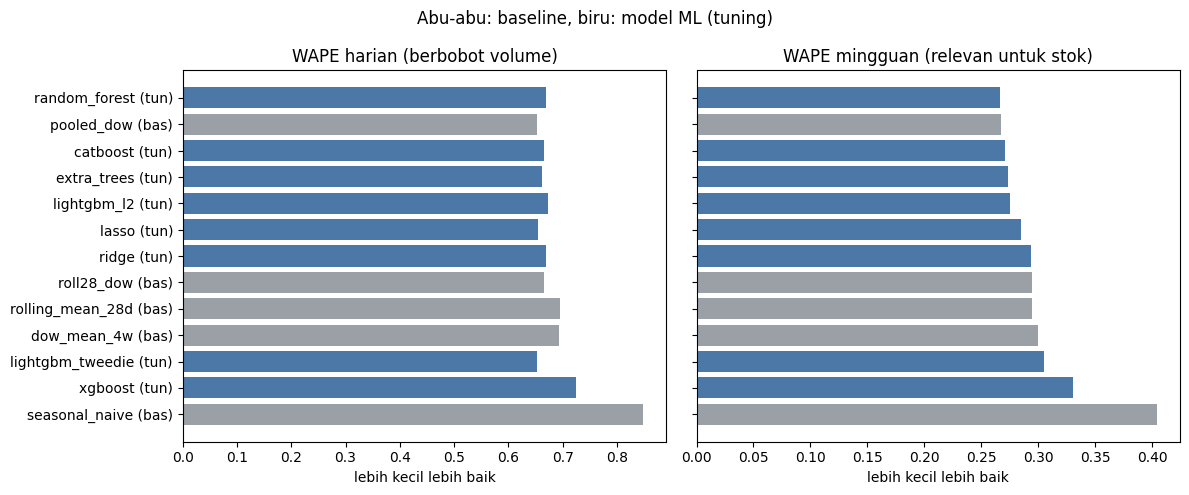

In [11]:
plot = summary[summary.config.isin(['baseline', 'tuning'])].sort_values('WAPE_mingguan', ascending=False)
labels = [f'{m} ({c[:3]})' for m, c in zip(plot.model, plot.config)]
colors = ['#9AA0A6' if c == 'baseline' else '#4C78A8' for c in plot.config]
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ax[0].barh(labels, plot.WAPE_weighted, color=colors)
ax[0].set_title('WAPE harian (berbobot volume)')
ax[1].barh(labels, plot.WAPE_mingguan, color=colors)
ax[1].set_title('WAPE mingguan (relevan untuk stok)')
for a in ax:
    a.set_xlabel('lebih kecil lebih baik')
plt.suptitle('Abu-abu: baseline, biru: model ML (tuning)')
plt.tight_layout()
plt.show()

In [12]:
print('WAPE mingguan per kelompok bahan (rata-rata dua lipatan):')
sel = results_group[results_group.config.isin(['baseline', 'tuning'])]
(sel.pivot_table(index='model', columns='group', values='WAPE_mingguan', aggfunc='mean')
 [GROUPS].round(3).sort_values('rutin'))

WAPE mingguan per kelompok bahan (rata-rata dua lipatan):


group,rutin,jarang,sangat_jarang
model,,,
random_forest,0.190,0.531,1.048
catboost,0.200,0.516,1.047
pooled_dow,0.200,0.500,1.014
lightgbm_l2,0.201,0.533,1.073
extra_trees,0.206,0.506,1.020
roll28_dow,0.223,0.544,1.026
rolling_mean_28d,0.223,0.545,1.027
lasso,0.224,0.496,0.992
dow_mean_4w,0.228,0.551,1.087


### Pengaruh tuning hyperparameter

Selisih `bawaan` terhadap `tuning` (rata-rata dua lipatan). Selisih negatif = tuning memperbaiki.

In [13]:
t = summary[summary.config.isin(['bawaan', 'tuning'])].pivot(index='model', columns='config',
                                                            values=['WAPE_weighted', 'WAPE_mingguan'])
effect = pd.DataFrame({
    'WAPE_harian_bawaan': t['WAPE_weighted']['bawaan'], 'WAPE_harian_tuning': t['WAPE_weighted']['tuning'],
    'WAPE_mingguan_bawaan': t['WAPE_mingguan']['bawaan'], 'WAPE_mingguan_tuning': t['WAPE_mingguan']['tuning'],
})
effect['selisih_mingguan'] = effect['WAPE_mingguan_tuning'] - effect['WAPE_mingguan_bawaan']
effect.round(3).sort_values('selisih_mingguan')

,WAPE_harian_bawaan,WAPE_harian_tuning,WAPE_mingguan_bawaan,WAPE_mingguan_tuning,selisih_mingguan
model,,,,,
xgboost,0.810,0.724,0.443,0.330,-0.112
catboost,0.684,0.666,0.299,0.271,-0.028
random_forest,0.678,0.669,0.276,0.266,-0.010
lasso,0.673,0.655,0.294,0.285,-0.009
extra_trees,0.669,0.662,0.279,0.273,-0.005
lightgbm_l2,0.669,0.673,0.280,0.275,-0.004
ridge,0.676,0.670,0.295,0.294,-0.000
lightgbm_tweedie,0.651,0.653,0.293,0.305,0.012


## 10. Memilih model

Aturan pemilihan: model ML (konfigurasi `tuning`) dengan WAPE mingguan rata-rata terendah. Hasilnya dibandingkan dengan baseline `pooled_dow` (level bahan x faktor hari) sebagai pembanding wajib: bila model ML tidak mengalahkannya secara andal, itu temuan yang perlu dicatat, bukan disembunyikan.

In [14]:
ml = summary[(summary.config == 'tuning')].sort_values('WAPE_mingguan')
BEST_MODEL = ml.iloc[0]['model']
pooled = summary[summary.model == 'pooled_dow'].iloc[0]
print('Model ML terpilih:', BEST_MODEL)
print(f'  WAPE mingguan ML  : {ml.iloc[0].WAPE_mingguan:.3f} | bias mingguan {ml.iloc[0].bias_mingguan_pct:+.1f}%')
print(f'  WAPE mingguan pooled_dow: {pooled.WAPE_mingguan:.3f} | bias mingguan {pooled.bias_mingguan_pct:+.1f}%')
gap = pooled.WAPE_mingguan - ml.iloc[0].WAPE_mingguan
print(f'  Keunggulan ML atas baseline: {gap:+.3f} (selisih di bawah ~0,02 dianggap tidak meyakinkan)')
BEST_PARAMS = best_by_fold['B_okt'][BEST_MODEL]
print('Parameter (lipatan terbaru):', BEST_PARAMS)

Model ML terpilih: random_forest
  WAPE mingguan ML  : 0.266 | bias mingguan +0.3%
  WAPE mingguan pooled_dow: 0.268 | bias mingguan -2.6%
  Keunggulan ML atas baseline: +0.001 (selisih di bawah ~0,02 dianggap tidak meyakinkan)
Parameter (lipatan terbaru): {'max_depth': 6, 'min_samples_leaf': 20}


## 11. Model final dan forecast 7 hari ke depan

Model dilatih pada seluruh data sampai tanggal terakhir, lalu meramal 7 hari berikutnya. Fitur untuk hari-hari itu hanya memakai data yang berumur >= 7 hari, jadi tersedia seluruhnya.

In [15]:
last_date = matrix.columns.max()
future_days = pd.date_range(last_date + pd.Timedelta(days=1), periods=7, freq='D')
extended = matrix.copy()
for d in future_days:
    extended[d] = 0.0  # tempat kosong; nilainya tidak pernah dipakai sebagai fitur

info_final = ingredient_groups(matrix, last_date)
panel_full = build_panel(extended, ingredients, info_final)
train_full = panel_full[panel_full.date <= last_date].reset_index(drop=True)
future = panel_full[panel_full.date > last_date].reset_index(drop=True)
cols_final = list(feature_matrix(train_full).columns)
assert future.date.nunique() == 7, 'fitur 7 hari ke depan harus lengkap'

final_model = MODELS[BEST_MODEL][0](**BEST_PARAMS)
final_model.fit(feature_matrix(train_full, cols_final), train_full['y'])
future['pred_norm'] = final_model.predict(feature_matrix(future, cols_final))
future['pred'] = np.clip(future['pred_norm'], 0, None) * future['scale']
future['pred_pooled_dow'] = np.clip(future['pooled_dow'], 0, None) * future['scale']

names = ingredients.set_index('ingredient_id')['ingredient_name']
forecast = future[['ingredient_id', 'date', 'group', 'pred', 'pred_pooled_dow']].copy()
forecast.insert(1, 'ingredient_name', forecast['ingredient_id'].map(names))
forecast = forecast.rename(columns={'pred': f'forecast_{BEST_MODEL}', 'pred_pooled_dow': 'forecast_pooled_dow'})
forecast.to_csv(OUT / 'forecast_7_hari.csv', index=False)
print('Forecast', future_days.min().date(), 'sampai', future_days.max().date(), '|', forecast.ingredient_id.nunique(), 'bahan')
forecast.head(10).round(1)

Forecast 2026-11-01 sampai 2026-11-07 | 97 bahan


,ingredient_id,ingredient_name,date,group,forecast_random_forest,forecast_pooled_dow
0,ING001,Ayam Potong (Paha/Dada),2026-11-01,rutin,249.8,290.7
1,ING001,Ayam Potong (Paha/Dada),2026-11-02,rutin,197.1,202.7
2,ING001,Ayam Potong (Paha/Dada),2026-11-03,rutin,188.9,237.9
3,ING001,Ayam Potong (Paha/Dada),2026-11-04,rutin,189.9,206.3
4,ING001,Ayam Potong (Paha/Dada),2026-11-05,rutin,205.4,188.9
5,ING001,Ayam Potong (Paha/Dada),2026-11-06,rutin,238.9,305.4
6,ING001,Ayam Potong (Paha/Dada),2026-11-07,rutin,238.8,298.7
7,ING002,Ayam Fillet Dada,2026-11-01,rutin,549.3,642.6
8,ING002,Ayam Fillet Dada,2026-11-02,rutin,450.0,446.9
9,ING002,Ayam Fillet Dada,2026-11-03,rutin,461.8,523.3


## 12. Saran stok

Untuk tiap bahan:

- `hari_cakupan = min(7, umur simpan)`: protein dan sayur tidak disarankan dibeli melebihi masa simpannya.
- `kebutuhan = jumlah forecast selama hari_cakupan`.
- `safety_stock` dari **galat peramalan mingguan hasil backtest** (kelompok bahan yang sama): persentil ke-`TINGKAT_LAYANAN` dari selisih (aktual - prediksi) per skala bahan, diperkecil dengan akar(hari_cakupan/7) untuk cakupan di bawah seminggu (asumsi, belum diuji).
- `target_stok = kebutuhan + safety_stock`; `saran_beli = max(0, target_stok - stok_saat_ini)`, dibulatkan ke atas (kelipatan 50 untuk gram/ml, 1 untuk pcs; asumsi, belum ada data kelipatan beli pemasok).
- Bahan **sangat jarang** (forecast tidak andal) dan **tanpa riwayat** memakai `minimum_stock` dari data bahan sebagai lantai/aturan manual.

**Stok saat ini tidak ada di dataset**, jadi diisi 0 sebagai tampungan sampai Anda mengisinya. Sel berikutnya membuat templat `stok_saat_ini.csv`; isi lalu jalankan ulang dari sel Saran stok.

In [16]:
TINGKAT_LAYANAN = 0.95   # peluang kebutuhan mingguan tertutup stok target
KELIPATAN = {'gram': 50, 'ml': 50, 'pcs': 1}   # asumsi pembulatan beli

# 12a. Galat backtest mingguan (aktual - prediksi) dibagi skala bahan, per kelompok.
def backtest_errors(model_col_suffix):
    frames = []
    for fold in FOLDS:
        w = weekly_table(preds[fold], model_col_suffix)
        w['fold'] = fold
        frames.append(w)
    w = pd.concat(frames)
    w['err_norm'] = (w['a'] - w['p']) / w['scale']
    return w


bt = backtest_errors(f'p_{BEST_MODEL}_tuning')
safety_q = bt.groupby('group')['err_norm'].quantile(TINGKAT_LAYANAN).clip(lower=0)
print('Safety stock per kelompok (kelipatan skala harian bahan, untuk cakupan 7 hari):')
print(safety_q.round(2).to_dict())

Safety stock per kelompok (kelipatan skala harian bahan, untuk cakupan 7 hari):
{'jarang': 9.05, 'rutin': 4.47, 'sangat_jarang': 28.11}


In [17]:
# 12b. Validasi aturan di luar sampel: kuantil dari lipatan A, diuji pada minggu-minggu lipatan B.
def evaluate_rule(pred_col_fold_b, q_from_a):
    wb = weekly_table(preds['B_okt'], pred_col_fold_b)
    wb['target'] = wb['p'] + wb['group'].map(q_from_a) * wb['scale']
    rows = []
    for g, f in [('semua', wb), *wb.groupby('group')]:
        rows.append({'kelompok': g,
                     'cakupan': float((f.target >= f.a).mean()),
                     'kelebihan_stok_pct_pemakaian': float(np.maximum(f.target - f.a, 0).sum() / f.a.sum() * 100)})
    return pd.DataFrame(rows).set_index('kelompok')


def q_from_fold_a(pred_col):
    w = weekly_table(preds['A_sep'], pred_col)
    err = (w['a'] - w['p']) / w['scale']
    return err.groupby(w['group']).quantile(TINGKAT_LAYANAN).clip(lower=0)


ml_col, pool_col = f'p_{BEST_MODEL}_tuning', 'pooled_dow'
rule_ml = evaluate_rule(ml_col, q_from_fold_a(ml_col))
rule_pool = evaluate_rule(pool_col, q_from_fold_a(pool_col))
print(f'Target cakupan: {TINGKAT_LAYANAN:.0%}. Kuantil dari September, diuji di Oktober (di luar sampel).')
print()
print(f'Model ML ({BEST_MODEL})')
print(rule_ml.round(3))
print()
print('Baseline pooled_dow')
print(rule_pool.round(3))

Target cakupan: 95%. Kuantil dari September, diuji di Oktober (di luar sampel).

Model ML (random_forest)
               cakupan  kelebihan_stok_pct_pemakaian
kelompok                                            
semua            0.961                        83.740
jarang           0.957                       141.300
rutin            0.956                        65.300
sangat_jarang    1.000                       613.015

Baseline pooled_dow
               cakupan  kelebihan_stok_pct_pemakaian
kelompok                                            
semua            0.979                       100.067
jarang           0.984                       167.153
rutin            0.969                        79.090
sangat_jarang    1.000                       641.148


In [18]:
# 12c. Templat stok saat ini (isi bila punya data) lalu hitung saran.
STOK_FILE = Path('stok_saat_ini.csv')
if not STOK_FILE.exists():
    template = ingredients[['ingredient_id', 'ingredient_name', 'base_unit']].assign(stok_saat_ini=0.0)
    template.to_csv(STOK_FILE, index=False)
    print('Templat dibuat:', STOK_FILE.resolve(), '(stok diisi 0; ganti dengan stok nyata)')
stok = pd.read_csv(STOK_FILE).set_index('ingredient_id')['stok_saat_ini']

static = ingredients.set_index('ingredient_id')
rows = []
for ing in ingredients.ingredient_id:
    s = static.loc[ing]
    group = info_final.loc[ing, 'group']
    shelf = int(s['shelf_life_days'])
    cover = int(min(7, max(shelf, 1)))
    current = float(stok.get(ing, 0.0))
    if group == 'tanpa_riwayat':
        need = safety = 0.0
        target = float(s['minimum_stock'])
        note = 'tanpa riwayat pemakaian: pakai minimum_stock'
    else:
        f = future[future.ingredient_id == ing].sort_values('date').head(cover)
        need = float(f['pred'].sum())
        scale = float(info_final.loc[ing, 'scale'])
        safety = float(safety_q.get(group, 0.0)) * scale * np.sqrt(cover / 7)
        target = need + safety
        note = ''
        if group == 'sangat_jarang':
            target = max(target, float(s['minimum_stock']))
            note = 'forecast tidak andal (sangat jarang): lantai minimum_stock'
        elif cover < 7:
            note = f'cakupan dibatasi umur simpan ({shelf} hari)'
    step = KELIPATAN.get(s['base_unit'], 1)
    buy = max(0.0, target - current)
    buy = float(np.ceil(buy / step) * step) if buy > 0 else 0.0
    rows.append({
        'ingredient_id': ing, 'ingredient_name': s['ingredient_name'], 'kategori': s['ingredient_category'],
        'satuan': s['base_unit'], 'kelompok': group, 'umur_simpan_hari': shelf, 'hari_cakupan': cover,
        'kebutuhan': round(need, 1), 'safety_stock': round(safety, 1), 'target_stok': round(target, 1),
        'stok_saat_ini': current, 'saran_beli': buy,
        'estimasi_biaya_idr': round(buy * float(s['reference_unit_cost_idr'])),
        'di_bawah_minimum_stock': current < float(s['minimum_stock']), 'catatan': note,
    })
advice = pd.DataFrame(rows)
advice.to_csv(OUT / 'saran_stok.csv', index=False)
print(f'{(advice.saran_beli > 0).sum()} dari {len(advice)} bahan perlu dibeli | total estimasi Rp {advice.estimasi_biaya_idr.sum():,.0f}')
advice.sort_values('estimasi_biaya_idr', ascending=False).head(15)

Templat dibuat: /content/stok_saat_ini.csv (stok diisi 0; ganti dengan stok nyata)
106 dari 106 bahan perlu dibeli | total estimasi Rp 2,256,235


,ingredient_id,ingredient_name,kategori,satuan,kelompok,umur_simpan_hari,hari_cakupan,kebutuhan,safety_stock,target_stok,stok_saat_ini,saran_beli,estimasi_biaya_idr,di_bawah_minimum_stock,catatan
11,ING012,Telur Ayam,protein,pcs,rutin,21,7,43.1,31.1,74.1,0.0,75.0,157500,True,
15,ING016,Beras,karbohidrat,gram,rutin,180,7,5087.9,3652.6,8740.6,0.0,8750.0,122500,True,
74,ING075,Madu,bumbu_saus,ml,tanpa_riwayat,365,7,0.0,0.0,1000.0,0.0,1000.0,100000,True,tanpa riwayat pemakaian: pakai minimum_stock
1,ING002,Ayam Fillet Dada,protein,gram,rutin,2,2,999.3,1317.4,2316.7,0.0,2350.0,98700,True,cakupan dibatasi umur simpan (2 hari)
2,ING003,Daging Sapi Slice,protein,gram,rutin,3,3,352.5,393.3,745.8,0.0,750.0,90000,True,cakupan dibatasi umur simpan (3 hari)
61,ING062,Minyak Goreng,bumbu_saus,ml,rutin,365,7,2612.9,1876.5,4489.5,0.0,4500.0,81000,True,
104,ING105,Mika Besar,kemasan,pcs,tanpa_riwayat,730,7,0.0,0.0,50.0,0.0,50.0,75000,True,tanpa riwayat pemakaian: pakai minimum_stock
103,ING104,Mika Tanggung,kemasan,pcs,tanpa_riwayat,730,7,0.0,0.0,50.0,0.0,50.0,55000,True,tanpa riwayat pemakaian: pakai minimum_stock
86,ING087,Bumbu Bali,bumbu_saus,gram,tanpa_riwayat,3,3,0.0,0.0,1000.0,0.0,1000.0,55000,True,tanpa riwayat pemakaian: pakai minimum_stock
85,ING086,Bumbu Acar,bumbu_saus,gram,tanpa_riwayat,3,3,0.0,0.0,1000.0,0.0,1000.0,50000,True,tanpa riwayat pemakaian: pakai minimum_stock


## 13. Simpan model dan unduh hasil

Model final disimpan beserta daftar fitur dan skala bahan, agar bisa dimuat untuk serving (FastAPI) tanpa melatih ulang.

In [19]:
joblib.dump({'model': final_model, 'model_name': BEST_MODEL, 'params': BEST_PARAMS, 'columns': cols_final,
             'last_date': str(last_date.date()), 'ingredient_info': info_final,
             'safety_quantiles': safety_q.to_dict(), 'service_level': TINGKAT_LAYANAN},
            OUT / 'model_forecast.joblib')
print('Berkas di', OUT.resolve())
for p in sorted(OUT.iterdir()):
    print(' ', p.name, f'({p.stat().st_size / 1024:.0f} KB)')

try:
    from google.colab import files
    import shutil
    shutil.make_archive('hasil_forecasting', 'zip', OUT)
    files.download('hasil_forecasting.zip')
except ImportError:
    pass  # bukan di Colab

Berkas di /content/hasil_forecasting
  best_params.json (2 KB)
  evaluasi_per_kelompok.csv (21 KB)
  evaluasi_semua_lipatan.csv (7 KB)
  forecast_7_hari.csv (49 KB)
  model_forecast.joblib (1554 KB)
  ringkasan_rata_rata_lipatan.csv (3 KB)
  saran_stok.csv (11 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Kesimpulan dan keterbatasan

Lihat tabel di bagian 9 dan 10 untuk angka pada data yang Anda jalankan. Hal yang perlu diingat:

- Prediksi harian per bahan sangat berisik (volume ±11 order per hari). Total mingguan jauh lebih akurat dan itulah yang dipakai untuk saran stok.
- Model ML dibandingkan dengan baseline `pooled_dow`. Bila selisihnya kecil atau tidak stabil antar lipatan, baseline sederhana setara dan lebih murah untuk dirawat.
- Bahan sangat jarang dan bahan tanpa riwayat (termasuk kemasan) tidak bisa diramal; gunakan aturan stok minimum.
- Data sintetis dan hanya 6 bulan: urutan model **tidak membuktikan** performa di data nyata. Tidak ada data stok historis, jadi yang teruji hanya akurasi forecast dan cakupan aturan stok pada backtest, bukan keberhasilan operasional.
- Safety stock untuk cakupan di bawah 7 hari, pembulatan beli, dan tingkat layanan adalah asumsi; sesuaikan dengan data pemasok nyata.
- Ulangi seluruh notebook saat data nyata tersedia sebelum memakai hasilnya untuk keputusan.